In [ ]:
from google.colab import files
uploaded = files.upload()

Saving fraud_detection_kaggle_style_1000_rows.csv to fraud_detection_kaggle_style_1000_rows.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

df = pd.read_csv("fraud_detection_kaggle_style_1000_rows.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (1000, 15)


,TransactionID,FraudIndicator,Category,TransactionAmount,AnomalyScore,Timestamp,MerchantID,Amount,CustomerID,Name,Age,Address,AccountBalance,LastLogin,SuspiciousFlag
0,522,0,Food,62.418039,0.118503,2022-01-22 17:00:00,2393,85.183528,1176,Customer 1176,47,Address 1176,5687.939606,2022-10-14,0
1,738,0,Online,58.918440,0.397612,2022-01-31 17:00:00,2853,89.732260,1826,Customer 1826,46,Address 1826,5510.464583,2024-03-09,0
2,741,0,Travel,53.622666,0.483040,2022-01-31 20:00:00,2568,76.232616,1493,Customer 1493,18,Address 1493,2432.431756,2023-11-25,0
3,661,0,Other,84.852734,0.163035,2022-01-28 12:00:00,2002,31.942174,1341,Customer 1341,34,Address 1341,2825.858583,2024-07-28,0
4,412,0,Other,37.294763,0.780376,2022-01-18 03:00:00,2071,79.340250,1720,Customer 1720,50,Address 1720,2634.682797,2023-08-08,0


In [ ]:
print("Dataset Information:")
df.info()

print("\nMissing Values in Each Column:")
display(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   TransactionID      1000 non-null   int64  
 1   FraudIndicator     1000 non-null   int64  
 2   Category           1000 non-null   object 
 3   TransactionAmount  1000 non-null   float64
 4   AnomalyScore       1000 non-null   float64
 5   Timestamp          1000 non-null   object 
 6   MerchantID         1000 non-null   int64  
 7   Amount             1000 non-null   float64
 8   CustomerID         1000 non-null   int64  
 9   Name               1000 non-null   object 
 10  Age                1000 non-null   int64  
 11  Address            1000 non-null   object 
 12  AccountBalance     1000 non-null   float64
 13  LastLogin          1000 non-null   object 
 14  SuspiciousFlag     1000 non-null   int64  
dtypes: float64(4), int64(6), object(5)
memory usage: 117

,0
TransactionID,0
FraudIndicator,0
Category,0
TransactionAmount,0
AnomalyScore,0
Timestamp,0
MerchantID,0
Amount,0
CustomerID,0
Name,0



Total Missing Values: 0

Duplicate Rows: 0


In [ ]:
print("Fraud Indicator Distribution:")
display(df["FraudIndicator"].value_counts().sort_index())

print("\nPercentage Distribution:")
display(
    (df["FraudIndicator"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

Fraud Indicator Distribution:


,count
FraudIndicator,
0,955
1,45



Percentage Distribution:


,proportion
FraudIndicator,
0,95.5
1,4.5


In [ ]:
print("Descriptive Statistical Analysis")

display(df.describe())

print("\nMedian of Numerical Columns:")
display(df.select_dtypes(include=np.number).median())

print("\nMode of Numerical Columns:")
display(df.select_dtypes(include=np.number).mode().iloc[0])

Descriptive Statistical Analysis


,TransactionID,FraudIndicator,TransactionAmount,AnomalyScore,MerchantID,Amount,CustomerID,Age,AccountBalance,SuspiciousFlag
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,0.045000,55.182288,0.495393,2516.704000,53.372803,1504.929000,40.390000,5448.725403,0.025000
std,288.819436,0.207408,25.892150,0.288592,291.901317,26.349810,289.998108,13.351785,2624.296876,0.156203
min,1.000000,0.000000,10.289644,0.000012,2001.000000,10.016788,1001.000000,18.000000,1005.647650,0.000000
25%,250.750000,0.000000,32.247920,0.259179,2255.750000,30.711935,1243.750000,29.000000,3137.873694,0.000000
50%,500.500000,0.000000,56.132083,0.489997,2507.000000,52.223884,1506.000000,40.000000,5484.812883,0.000000
75%,750.250000,0.000000,76.896404,0.738628,2780.250000,76.630200,1758.250000,52.000000,7573.152053,0.000000
max,1000.000000,1.000000,99.947235,0.997821,2999.000000,99.786054,1999.000000,64.000000,9998.643200,1.000000



Median of Numerical Columns:


,0
TransactionID,500.500000
FraudIndicator,0.000000
TransactionAmount,56.132083
AnomalyScore,0.489997
MerchantID,2507.000000
Amount,52.223884
CustomerID,1506.000000
Age,40.000000
AccountBalance,5484.812883
SuspiciousFlag,0.000000



Mode of Numerical Columns:


,0
TransactionID,1.000000
FraudIndicator,0.000000
TransactionAmount,10.289644
AnomalyScore,0.000012
MerchantID,2192.000000
Amount,10.016788
CustomerID,1099.000000
Age,29.000000
AccountBalance,1005.647650
SuspiciousFlag,0.000000


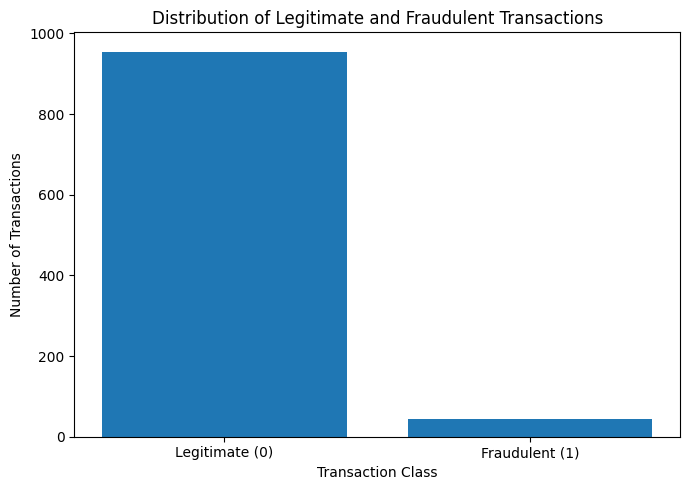

In [ ]:
fraud_counts = df["FraudIndicator"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(
    ["Legitimate (0)", "Fraudulent (1)"],
    [fraud_counts.get(0, 0), fraud_counts.get(1, 0)]
)
plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

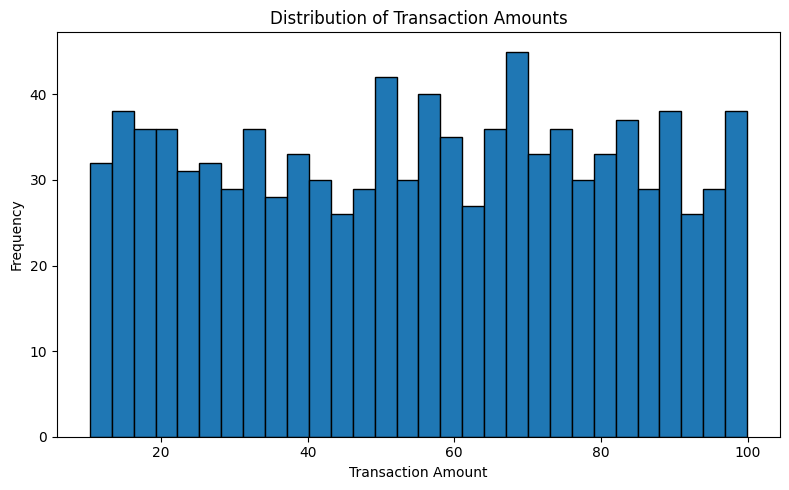

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df["TransactionAmount"], bins=30, edgecolor="black")
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

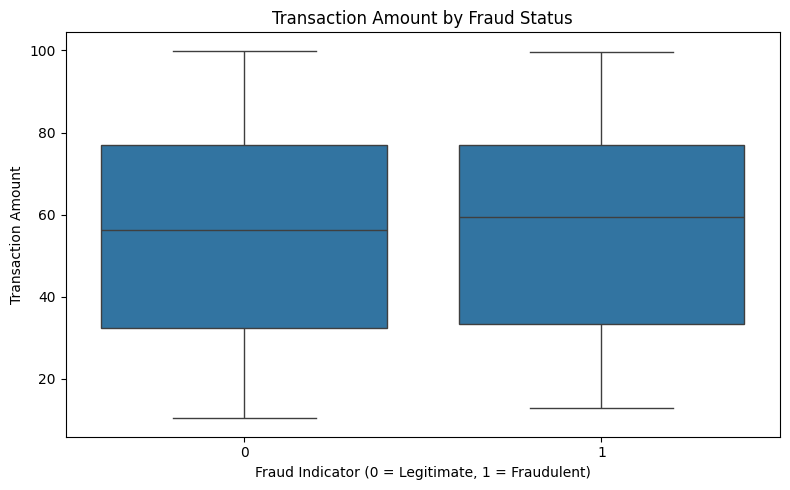

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="FraudIndicator",
    y="TransactionAmount"
)

plt.title("Transaction Amount by Fraud Status")
plt.xlabel("Fraud Indicator (0 = Legitimate, 1 = Fraudulent)")
plt.ylabel("Transaction Amount")
plt.tight_layout()
plt.show()

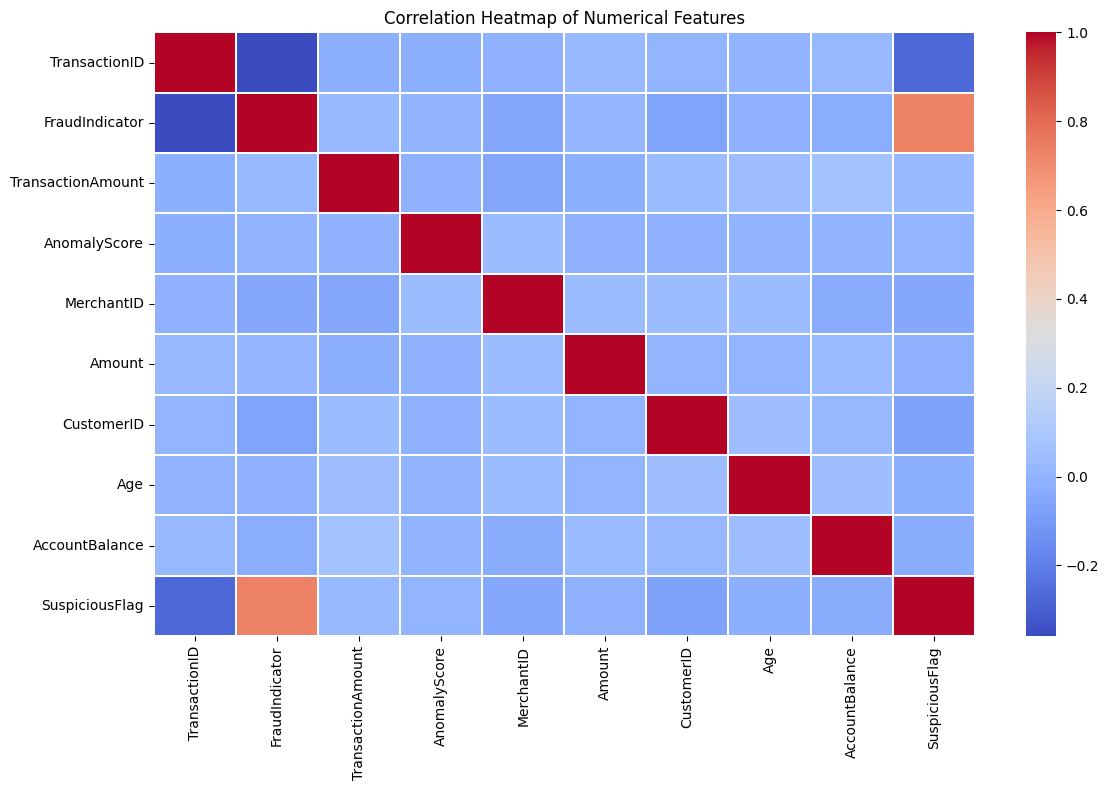

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    annot=False,
    linewidths=0.3
)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Create a working copy
model_df = df.copy()

# Convert transaction timestamp into hour of day
model_df["Timestamp"] = pd.to_datetime(
    model_df["Timestamp"], errors="coerce"
)
model_df["Hour"] = model_df["Timestamp"].dt.hour

# Calculate days between transaction and last login
model_df["LastLogin"] = pd.to_datetime(
    model_df["LastLogin"], errors="coerce"
)
model_df["gap"] = (
    model_df["Timestamp"] - model_df["LastLogin"]
).dt.days.abs()

# Select useful features
features = [
    "Category",
    "TransactionAmount",
    "AnomalyScore",
    "Amount",
    "AccountBalance",
    "SuspiciousFlag",
    "Hour",
    "gap"
]

X = model_df[features].copy()
y = model_df["FraudIndicator"].astype(int)

# Encode transaction category
encoder = LabelEncoder()
X["Category"] = encoder.fit_transform(X["Category"].astype(str))

# Handle any missing values in selected features
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

print("Features prepared successfully!")
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts().sort_index())

Features prepared successfully!
Feature shape: (1000, 8)
Target shape: (1000,)

Target distribution:
FraudIndicator
0    955
1     45
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Training data: (800, 8)
Testing data: (200, 8)

Training target distribution:
FraudIndicator
0    764
1     36
Name: count, dtype: int64

Testing target distribution:
FraudIndicator
0    191
1      9
Name: count, dtype: int64


In [ ]:
!pip -q install imbalanced-learn

from imblearn.over_sampling import SMOTE

print("Before SMOTE:")
print(y_train.value_counts().sort_index())

smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train, y_train
)
print("\nAfter SMOTE:")
print(y_train_balanced.value_counts().sort_index())

print("\nBalanced training shape:", X_train_balanced.shape)

Before SMOTE:
FraudIndicator
0    764
1     36
Name: count, dtype: int64

After SMOTE:
FraudIndicator
0    764
1    764
Name: count, dtype: int64

Balanced training shape: (1528, 8)


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42)),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

results = [
    {
        "Model": name,
        "Accuracy": accuracy_score(y_test, (pred := model.fit(X_train_balanced, y_train_balanced).predict(X_test))),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    }
    for name, model in models.items()
]

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.715,0.1129,0.7778,0.1972,0.7923
Decision Tree,0.900,0.2609,0.6667,0.3750,0.7888
Random Forest,0.970,0.6667,0.6667,0.6667,0.8287


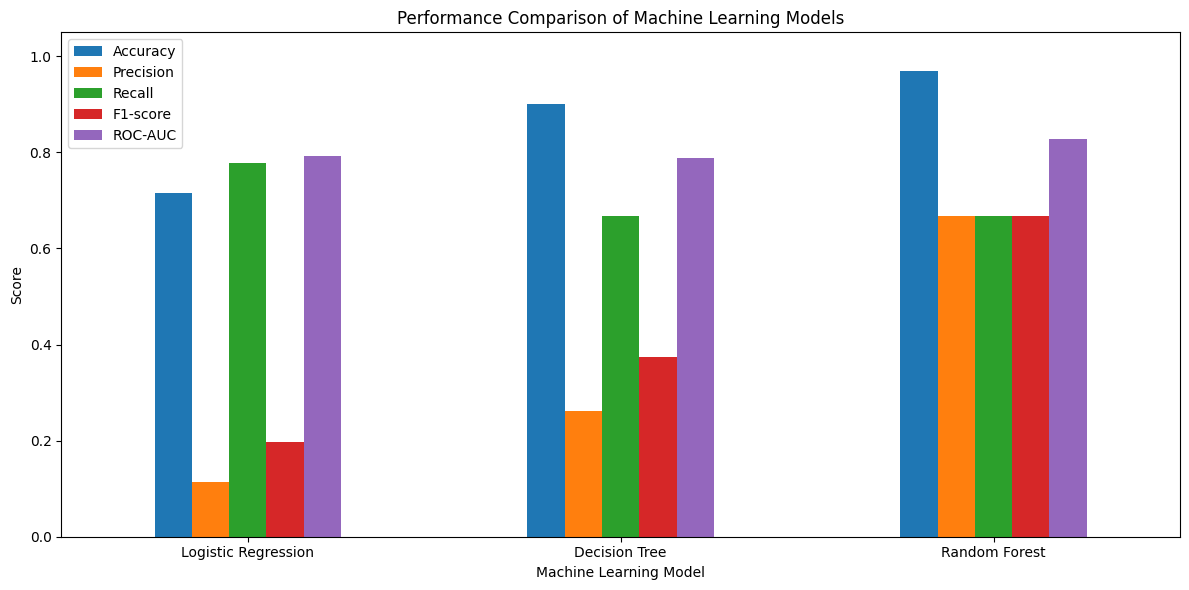

In [ ]:
metrics = [
    "Accuracy", "Precision", "Recall",
    "F1-score", "ROC-AUC"
]

results_df[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

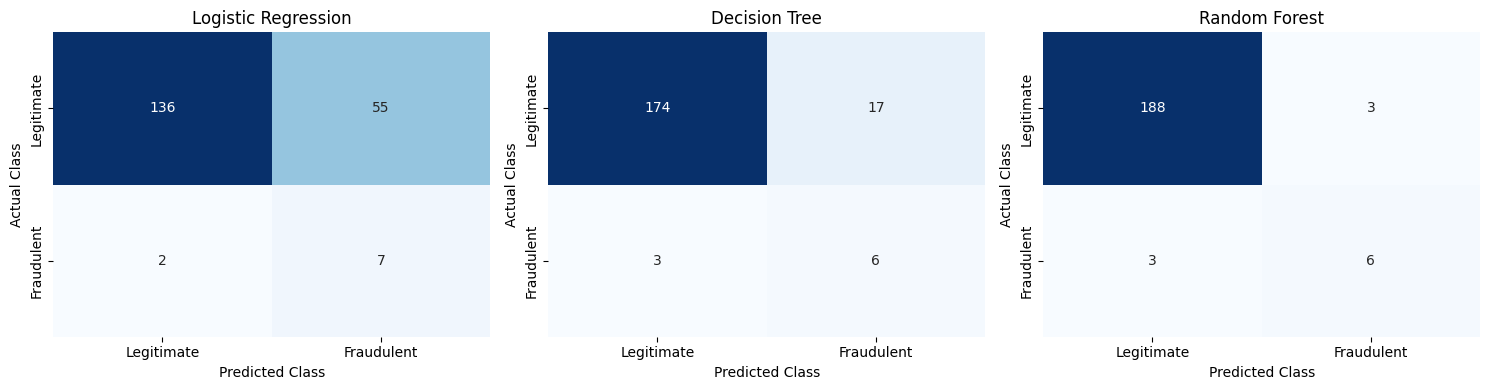

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, trained_models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax,
        xticklabels=["Legitimate", "Fraudulent"],
        yticklabels=["Legitimate", "Fraudulent"]
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [ ]:

for name, model in trained_models.items():
    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    y_pred = model.predict(X_test)

    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Legitimate", "Fraudulent"],
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

  Legitimate       0.99      0.71      0.83       191
  Fraudulent       0.11      0.78      0.20         9

    accuracy                           0.71       200
   macro avg       0.55      0.74      0.51       200
weighted avg       0.95      0.71      0.80       200


Decision Tree
              precision    recall  f1-score   support

  Legitimate       0.98      0.91      0.95       191
  Fraudulent       0.26      0.67      0.38         9

    accuracy                           0.90       200
   macro avg       0.62      0.79      0.66       200
weighted avg       0.95      0.90      0.92       200


Random Forest
              precision    recall  f1-score   support

  Legitimate       0.98      0.98      0.98       191
  Fraudulent       0.67      0.67      0.67         9

    accuracy                           0.97       200
   macro avg       0.83      0.83      0.83       200
weighted avg       0.97

In [ ]:

# Display final model comparison table
final_results = results_df.reset_index()

final_results = final_results.round(4)

print("FINAL MODEL COMPARISON")
display(final_results)

# Identify the model with the highest F1-score
best_model_name = results_df["F1-score"].idxmax()

print("Model with the highest F1-score:", best_model_name)
print(
    "F1-score:",
    round(results_df.loc[best_model_name, "F1-score"], 4)
)

# Save results as a CSV file
final_results.to_csv(
    "experiment6_model_comparison.csv",
    index=False
)

print("Results saved successfully!")


FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.715,0.1129,0.7778,0.1972,0.7923
1,Decision Tree,0.900,0.2609,0.6667,0.3750,0.7888
2,Random Forest,0.970,0.6667,0.6667,0.6667,0.8287


Model with the highest F1-score: Random Forest
F1-score: 0.6667
Results saved successfully!
